# Predicting CPE with Linear Regression
**Bakari Kerr**

This notebook compared ordinary least squares (OLS), Ridge regression, and product-price baselines for predicting cost per engagement (CPE). It used the same saved training/validation split as Timothy Hsu's XGBoost notebook to support comparison across model types.

The experiments examined the effects of target-derived features, regularization, unusual training labels, product information, and a restricted set of candidate planning features. Results were collected in a shared validation table.

The analysis used 335 training campaigns and 82 validation campaigns. Validation supported exploratory model comparison; it was not an untouched final test. The CPE results did not evaluate the project overview's H2 total-spend success criteria.


In [1]:
%pip install -q pandas numpy scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
# Optional: Path('/content/drive/MyDrive/your-folder/train_val_split')
DATA_DIR = None
FILENAMES = ['X_train.csv', 'X_val.csv', 'y_train.csv', 'y_val.csv']
if DATA_DIR is None:
    candidates = [Path.cwd() / 'data/train_val_split',
                  Path.cwd().parent / 'data/train_val_split', Path.cwd()]
    DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in FILENAMES)), None)
if DATA_DIR is None and 'google.colab' in sys.modules:
    from google.colab import files
    print('Upload X_train.csv, X_val.csv, y_train.csv, and y_val.csv together.')
    files.upload()
    DATA_DIR = Path.cwd()
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing the four split CSVs.')
DATA_DIR = Path(DATA_DIR)
missing_files = [f for f in FILENAMES if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing in {DATA_DIR}: {missing_files}')
X_train = pd.read_csv(DATA_DIR / 'X_train.csv')
X_val = pd.read_csv(DATA_DIR / 'X_val.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv')['cpe']
y_val = pd.read_csv(DATA_DIR / 'y_val.csv')['cpe']
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)
assert X_train.columns.equals(X_val.columns)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_val.to_numpy()).all()
assert np.isfinite(y_train).all() and np.isfinite(y_val).all()
print(f'Train: {X_train.shape}; validation: {X_val.shape}; folder: {DATA_DIR}')


Train: (335, 161); validation: (82, 161); folder: c:\Users\Bakari\OneDrive\Documents\Break Through Tech\Pharma-1A-predicting-pharma-ad-performance\data\train_val_split


## 1. Target and label provenance

The prepared CSVs contained numeric features and one-hot-encoded categories. Upstream cleaning had filled missing CPE values using budget divided by engagements. The `cpe_imputed` flag distinguished calculated labels from originally recorded labels; it was excluded from the restricted models.

Training contained five CPE values: $0.02 (1 campaign), $3 (113), $11 (1), $39 (195), and $68 (25). Validation contained only $3 (32), $39 (48), and $68 (2). The $0.02 label had been calculated upstream; the $11 label had been originally recorded. Their rarity alone did not establish that either was incorrect.

Of the training labels, 75 were calculated upstream: 74 at $39 and one at $0.02. Validation included 18 calculated labels and 64 originally observed labels. Consequently, performance at $68 rested on only two validation examples, and performance at $0.02 or $11 was not tested.

The upstream split assigned later-starting campaigns to validation. Ridge tuning used shuffled five-fold cross-validation within training because the exported rows were not guaranteed to be sorted by date. Encoding had already been fitted on the full training partition rather than separately within each CV fold. These CV estimates therefore did not represent a complete date-aware forecasting evaluation.


,train,validation
cpe,,
0.02,1,0.0
3.00,113,32.0
11.00,1,0.0
39.00,195,48.0
68.00,25,2.0


cpe,0.02,3.00,11.00,39.00,68.00
row_0,,,,,
BRAND ALERT,0,0,0,121,0
BRAND PLAY,0,0,0,7,0
BRANDSPOT,0,0,0,0,25
EMAIL ALERT,0,113,0,0,0
INFOSITE,0,0,0,24,0
POINT OF CONTACT,0,0,0,10,0
TARGET LIST MEDIA,1,0,0,24,0
infrequent_sklearn,0,0,1,9,0


cpe,0.02,3.00,11.00,39.00,68.00
CPE calculated upstream,,,,,
0,0,113,1,121,25
1,1,0,0,74,0


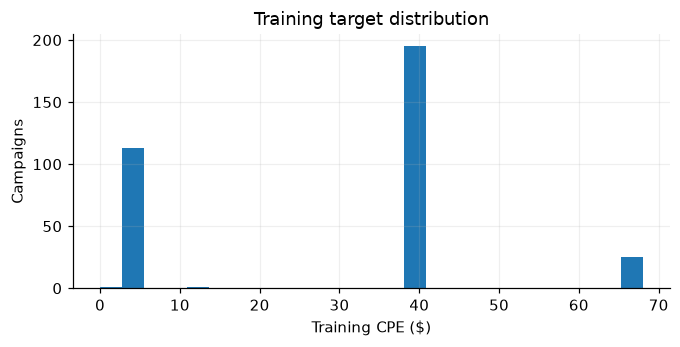

In [3]:
sub_cols = [c for c in X_train if c.startswith('sub_product_name_')]
assert sub_cols, 'Expected one-hot sub_product_name columns.'
def product_labels(X):
    labels = X[sub_cols].idxmax(axis=1).str.replace('sub_product_name_', '', regex=False)
    return labels.where(X[sub_cols].sum(axis=1) > 0, 'UNKNOWN')
sub_train, sub_val = product_labels(X_train), product_labels(X_val)
display(pd.concat([y_train.value_counts().rename('train'),
                   y_val.value_counts().rename('validation')], axis=1).fillna(0).sort_index())
display(pd.crosstab(sub_train, y_train))
if 'cpe_imputed' in X_train:
    display(pd.crosstab(X_train['cpe_imputed'].rename('CPE calculated upstream'), y_train))
y_train.hist(bins=25, figsize=(7, 3))
plt.xlabel('Training CPE ($)'); plt.ylabel('Campaigns'); plt.title('Training target distribution')
plt.show()


## 2. Shared scoring and models

All experiments were evaluated with MAE, RMSE, R-squared, and the fraction of predictions within $1 of the actual CPE, matching Timothy's scoring approach. MAE and RMSE were expressed in CPE dollars. Predictions were retained on their original scale, including negative values, and negative predictions were counted separately.

OLS fitted an unregularized linear model. Ridge added a penalty on coefficient magnitude to reduce sensitivity to overlapping predictors. Each model included a standardization step fitted within its pipeline. Ridge's penalty strength, alpha, was selected from 15 values between 0.001 and 10,000 using five-fold training CV and mean absolute error. OLS had no corresponding penalty to tune.

Full one-hot encodings and redundant predictors limited the interpretation of individual coefficients. Product ablation and permutation importance provided additional views of the information used by the models.


In [4]:
results, predictions, fitted = [], {}, {}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def metrics(actual, pred):
    return {'MAE': mean_absolute_error(actual, pred),
            'RMSE': np.sqrt(mean_squared_error(actual, pred)),
            'R2': r2_score(actual, pred) if len(actual) > 1 else np.nan,
            'within_$1': np.mean(np.abs(np.asarray(actual) - pred) <= 1)}
def score(name, pred, notes=''):
    pred = np.asarray(pred)
    predictions[name] = pred
    results.append({'experiment': name, **metrics(y_val, pred),
                    'negative_predictions': int((pred < 0).sum()), 'notes': notes})
    display(pd.DataFrame(results[-1:]).round(4))
def pipeline(ridge=False):
    return Pipeline([('scale', StandardScaler()),
                     ('model', Ridge() if ridge else LinearRegression())])
def fit_score(name, train, val, labels=y_train, ridge=False, notes=''):
    if ridge:
        search = GridSearchCV(pipeline(True), {'model__alpha': np.logspace(-3, 4, 15)},
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
        search.fit(train, labels)
        model = search.best_estimator_
        print(f'{name}: alpha={search.best_params_["model__alpha"]:g}; CV MAE=${-search.best_score_:.4f}')
    else:
        model = pipeline().fit(train, labels)
    fitted[name] = model
    print(f'Training MAE: ${mean_absolute_error(labels, model.predict(train)):.4f}')
    score(name, model.predict(val), notes)
    return model


## 3. Baselines and all-feature OLS

Two baselines established the reference performance. The mean baseline assigned the training mean CPE to every validation campaign. The product lookup assigned each sub-product's training median CPE, with the overall training median as a fallback for unseen groups.

The mean baseline had validation MAE $16.9905. The product lookup had zero validation error, indicating that product-level prices already explained the validation labels.

OLS was also fitted to all 161 features to mirror Timothy's initial experiment. Its error rounded to zero, but the inputs included target-derived and post-campaign information. This result illustrated the limitations of evaluating an unrestricted feature set as a forecasting model.


In [5]:
score('E0a Mean baseline', np.full(len(y_val), y_train.mean()))
rate_card = y_train.groupby(sub_train).median()
score('E0b Product lookup', sub_val.map(rate_card).fillna(y_train.median()).to_numpy(),
      'Training-only product medians')
ols_all = fit_score('E1 OLS all features', X_train, X_val, notes='Includes target-derived and outcome features')


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E0a Mean baseline,16.9905,18.9281,-0.0287,0.0,0,


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E0b Product lookup,0.0,0.0,1.0,1.0,0,Training-only product medians


Training MAE: $0.0000


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E1 OLS all features,0.0,0.0,1.0,1.0,0,Includes target-derived and outcome features


## 4. OLS and Ridge with Timothy's exclusions

For a direct comparison, the experiments removed Timothy's budget-related features, CPE flags, and product-tier indicators. The calculated $0.02 training label was excluded as a sensitivity choice, leaving 334 training rows and 149 features. All validation rows were retained.

OLS achieved MAE $0.9115, RMSE $2.9626, and R-squared 0.9748. Ridge selected alpha 0.0316228 and achieved MAE $0.8964, RMSE $2.9083, and R-squared 0.9757. Regularization improved error modestly. Each model produced one negative validation prediction.

The remaining features still included actual spending and engagement outcomes. These experiments supported comparison with Timothy's models but did not establish pre-campaign forecasting performance. Neither model improved on the product lookup.


In [6]:
leaky = ['total_budget_spent', 'log_total_budget_spent', 'budget_per_reach', 'budget_per_day',
         'spend_near_zero', 'budget_anomaly', 'cpe_imputed', 'cpe_outlier']
leaky += [c for c in X_train if c.startswith('product_tier_')]
comparison_cols = [c for c in X_train if c not in leaky]
keep = y_train.ne(0.02)
Xtr, Xv = X_train.loc[keep, comparison_cols], X_val[comparison_cols]
ytr = y_train.loc[keep]
print(f'{len(Xtr)} training rows; {len(comparison_cols)} features')
ols_clean = fit_score('E2 OLS Timothy exclusions', Xtr, Xv, ytr)
ridge_clean = fit_score('E3 Ridge Timothy exclusions', Xtr, Xv, ytr, ridge=True)


334 training rows; 149 features
Training MAE: $0.3205


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E2 OLS Timothy exclusions,0.9115,2.9626,0.9748,0.878,1,


E3 Ridge Timothy exclusions: alpha=0.0316228; CV MAE=$0.4986
Training MAE: $0.3166


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E3 Ridge Timothy exclusions,0.8964,2.9083,0.9757,0.8902,1,


## 5. Label sensitivity, product-only OLS, and product ablation

Three experiments examined the effects of an unusual label and product information.

**Label sensitivity:** Ridge was refitted after excluding the single $11 training example in addition to the $0.02 example. Validation MAE fell to approximately $0.0001. This showed that the rare training label strongly affected fitting. Since validation contained no $11 examples, the improvement did not establish that removing that label was an appropriate cleaning decision.

**Product-only OLS:** a linear model was fitted using only the sub-product indicator columns, retaining the $11 example. It achieved MAE $0.1024, RMSE $0.5356, and R-squared 0.9992, with 96.34% of predictions within $1. OLS estimated category means, whereas the lookup used medians. The grouped `infrequent_sklearn` category contained one $11 label and nine $39 labels, giving a training mean of $36.20. Its three validation campaigns had CPE $39, accounting for the product-only model's residual errors.

**Product ablation:** sub-product, channel, raw-brand indicators, and the specified product flags were removed, matching Timothy's ablation. Ridge MAE increased to $8.8094, with R-squared 0.6330 and 7.32% of predictions within $1. Five predictions were negative. Other product proxies remained, so this experiment measured the effect of removing the specified indicators rather than all product information.


In [7]:
keep11 = ytr.ne(11)
_ = fit_score('E4 Ridge without $11', Xtr.loc[keep11], Xv, ytr.loc[keep11], ridge=True,
              notes='Sensitivity only; both unusual training labels excluded')
product_ols = fit_score('E5 Product-only OLS', X_train.loc[keep, sub_cols], X_val[sub_cols], ytr)
product_feats = [c for c in Xtr if c.startswith(('sub_product_name_', 'channel_tag_', 'brand_raw_'))
                 or c in ['is_email_alert', 'is_brandspot', 'is_target_list', 'has_channel_tag']]
_ = fit_score('E6 Ridge product ablation', Xtr.drop(columns=product_feats),
              Xv.drop(columns=product_feats), ytr, ridge=True,
              notes='Matches Timothy ablation; other product proxies remain')


E4 Ridge without $11: alpha=0.001; CV MAE=$0.0001
Training MAE: $0.0000


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E4 Ridge without $11,0.0001,0.0001,1.0,1.0,0,Sensitivity only; both unusual training labels...


Training MAE: $0.1509


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E5 Product-only OLS,0.1024,0.5356,0.9992,0.9634,0,


E6 Ridge product ablation: alpha=100; CV MAE=$11.8708
Training MAE: $9.6320


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E6 Ridge product ablation,8.8094,11.3048,0.633,0.0732,5,Matches Timothy ablation; other product proxie...


## 6. Ridge with candidate planning features

A restricted set of 99 features represented information that could plausibly be available when planning a campaign: product and advertiser descriptors, audience and geographic descriptors, calendar variables, and baseline prescription measures. Actual spend, engagement outcomes, post-campaign prescription results, budget-derived features, target-derived flags, and product-tier columns were excluded. Campaign age was also excluded because its reference date was unclear.

The main model retained all 335 training labels. Ridge selected alpha 1 and achieved validation MAE $1.1858, RMSE $1.5053, and R-squared 0.9935. Of its predictions, 52.44% were within $1, and none were negative. Despite its high R-squared, the model had greater error than the product-only model and product lookup.

A second model used only the 260 originally observed training labels, excluding calculated labels. It selected alpha 0.001 and achieved validation MAE $3.0351, RMSE $7.1262, and R-squared 0.8542; 78.05% of predictions were within $1. Its higher within-$1 rate alongside worse MAE and RMSE indicated that a smaller share of larger errors outweighed many close predictions. Removing calculated labels also changed training coverage, so this comparison did not isolate label quality alone.

These were candidate planning models: the analysis did not independently verify that every retained descriptor and baseline measure was available at prediction time. Product-tier columns were explicitly excluded and checked by assertions in the final feature selector.


In [8]:
planning_prefixes = ('sub_product_name_', 'company_', 'product_', 'channel_tag_',
                     'country_', 'pillar_', 'media_type_', 'profession_', 'specialty_',
                     'npi_specialty_', 'region_')
planning_numeric = {'start_year', 'start_quarter', 'start_month', 'pre_NRx',
                    'pre_avg_NRx', 'pre_NRx_avg', 'has_specialty', 'is_us'}
planning_excluded = set(leaky) | {'cpe'}
planning_cols = [c for c in X_train
                 if (c.startswith(planning_prefixes) or c in planning_numeric)
                 and c not in planning_excluded]
assert not any(c.startswith('product_tier_') for c in planning_cols)
assert not (set(planning_cols) & planning_excluded)
# Allow rerunning this section without duplicating E7/E8 in the report.
rerun_names = {'E7 Ridge planning candidates', 'E8 Ridge observed labels only'}
results[:] = [row for row in results if row['experiment'] not in rerun_names]
for name in rerun_names:
    predictions.pop(name, None)
    fitted.pop(name, None)
assert planning_cols
print('Candidate planning features:', len(planning_cols))
print(planning_cols)
planning_model = fit_score('E7 Ridge planning candidates', X_train[planning_cols],
                           X_val[planning_cols], ridge=True,
                           notes='All training labels; candidate availability needs confirmation')
if 'cpe_imputed' in X_train:
    observed = X_train['cpe_imputed'].eq(0)
    if observed.sum() >= 10:
        _ = fit_score('E8 Ridge observed labels only', X_train.loc[observed, planning_cols],
                      X_val[planning_cols], y_train.loc[observed], ridge=True,
                      notes='Training uses originally observed CPE only')


Candidate planning features: 99
['start_year', 'start_quarter', 'start_month', 'pre_NRx', 'pre_avg_NRx', 'pre_NRx_avg', 'has_specialty', 'region_country_mismatch', 'is_us', 'company_ABBVIE', 'company_ASTRAZENECA', 'company_BOEHRINGER INGELHEIM', 'company_BRISTOL MYERS SQUIBB', 'company_EMD SERONO', 'company_GILEAD', 'company_GSK', 'company_HORIZON', 'company_JANSSEN', 'company_LILLY', 'company_MERCK', 'company_NEUROCRINE', 'company_NOVARTIS', 'company_SEAGEN', 'company_SERVIER', 'company_TAKEDA', 'company_VIIV HEALTHCARE', 'company_infrequent_sklearn', 'product_ADCETRIS', 'product_ENHERTU', 'product_MOUNJARO', 'product_unspecified', 'product_infrequent_sklearn', 'channel_tag_MDALERT', 'channel_tag_MEDSCAPE', 'channel_tag_ZS', 'channel_tag_none', 'channel_tag_infrequent_sklearn', 'sub_product_name_BRAND ALERT', 'sub_product_name_BRAND PLAY', 'sub_product_name_BRANDSPOT', 'sub_product_name_EMAIL ALERT', 'sub_product_name_INFOSITE', 'sub_product_name_POINT OF CONTACT', 'sub_product_name_T

,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E7 Ridge planning candidates,1.1858,1.5053,0.9935,0.5244,0,All training labels; candidate availability ne...


E8 Ridge observed labels only: alpha=0.001; CV MAE=$0.0654
Training MAE: $0.0001


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E8 Ridge observed labels only,3.0351,7.1262,0.8542,0.7805,0,Training uses originally observed CPE only


## 7. Validation diagnostics

Diagnostics focused on the all-label planning candidate model (E7), using residuals defined as actual CPE minus predicted CPE. Errors were summarized by product group and by whether the validation label had been calculated upstream.

MAE was $1.1577 for the 64 originally observed validation labels and $1.2861 for the 18 calculated labels. Among product groups, Target List Media had MAE $1.5036 across six campaigns, while Email Alert had MAE $1.1281 across 32 campaigns. Estimates for groups with very few examples were less informative.

The largest absolute error was $3.5171: an Email Alert campaign with actual CPE $3 was predicted at approximately $6.52. The scatter and residual plots described error across the common validation prices; they provided no evidence about the unusual prices absent from validation.


,rows,MAE
cpe_imputed,,
0,64,1.157655
1,18,1.286051


,rows,MAE
sub_product,,
BRAND ALERT,30,1.242871
BRAND PLAY,4,0.996917
BRANDSPOT,2,0.352425
EMAIL ALERT,32,1.128092
INFOSITE,4,1.321313
POINT OF CONTACT,1,0.409384
TARGET LIST MEDIA,6,1.503640
infrequent_sklearn,3,1.481589


,actual_cpe,predicted_cpe,sub_product,residual,absolute_error,cpe_imputed
61,3.0,6.517106,EMAIL ALERT,-3.517106,3.517106,0
51,39.0,35.809121,infrequent_sklearn,3.190879,3.190879,1
80,39.0,35.992732,TARGET LIST MEDIA,3.007268,3.007268,1
57,3.0,5.992436,EMAIL ALERT,-2.992436,2.992436,0
6,39.0,41.907523,BRAND ALERT,-2.907523,2.907523,0
62,3.0,5.860479,EMAIL ALERT,-2.860479,2.860479,0
45,39.0,41.802358,BRAND ALERT,-2.802358,2.802358,0
48,39.0,41.707856,BRAND ALERT,-2.707856,2.707856,0
16,39.0,41.686285,BRAND ALERT,-2.686285,2.686285,0
7,39.0,41.680762,BRAND ALERT,-2.680762,2.680762,0


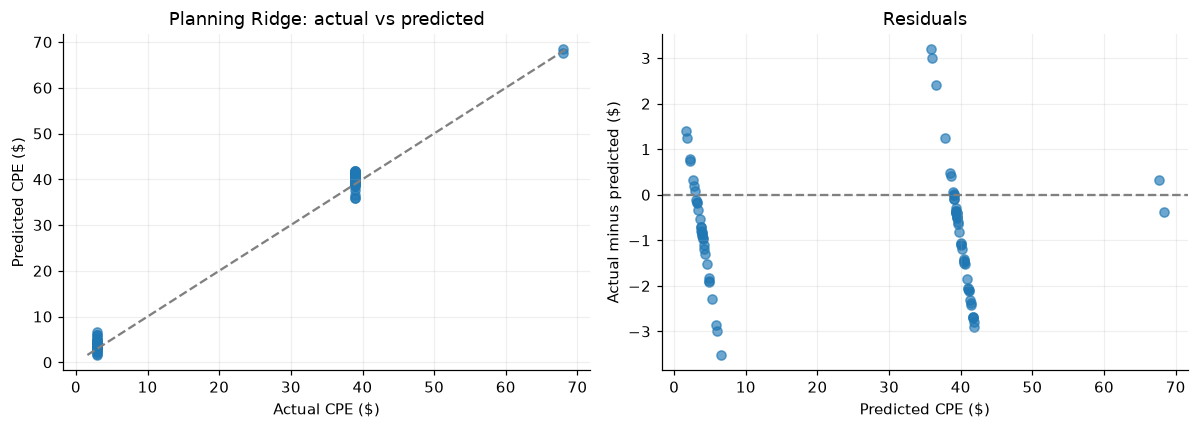

In [9]:
pred = predictions['E7 Ridge planning candidates']
diagnostics = pd.DataFrame({'actual_cpe': y_val, 'predicted_cpe': pred,
                            'sub_product': sub_val})
diagnostics['residual'] = diagnostics.actual_cpe - diagnostics.predicted_cpe
diagnostics['absolute_error'] = diagnostics.residual.abs()
if 'cpe_imputed' in X_val:
    diagnostics['cpe_imputed'] = X_val['cpe_imputed']
    display(diagnostics.groupby('cpe_imputed').agg(rows=('absolute_error', 'size'),
                                                 MAE=('absolute_error', 'mean')))
display(diagnostics.groupby('sub_product').agg(rows=('absolute_error', 'size'),
                                              MAE=('absolute_error', 'mean')))
display(diagnostics.sort_values('absolute_error', ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_val, pred, alpha=0.65)
lo, hi = min(y_val.min(), pred.min()), max(y_val.max(), pred.max())
axes[0].plot([lo, hi], [lo, hi], '--', color='gray')
axes[0].set(xlabel='Actual CPE ($)', ylabel='Predicted CPE ($)', title='Planning Ridge: actual vs predicted')
axes[1].scatter(pred, diagnostics.residual, alpha=0.65)
axes[1].axhline(0, linestyle='--', color='gray')
axes[1].set(xlabel='Predicted CPE ($)', ylabel='Actual minus predicted ($)', title='Residuals')
plt.tight_layout(); plt.show()


## 8. Feature interpretation

The planning candidate model was examined using standardized Ridge coefficients and validation permutation importance. Each coefficient represented a one-training-standard-deviation change in an input. For category indicators, that scale differed from a direct category-versus-reference price comparison.

Permutation importance measured the increase in validation MAE after one feature was shuffled. The Email Alert indicator had the largest increase ($11.8261), followed by Brand Alert ($3.1363) and BrandSpot ($1.7935). Start month and start quarter also contributed to the fitted model, with increases of approximately $1.00 and $0.92. Together with the product-only and ablation experiments, these results supported product type as the central predictive signal.

Correlated features could share effects, and shuffling an individual one-hot column could create invalid category combinations. Coefficients and permutation scores therefore described model behavior rather than causal effects. Calendar importance did not establish a seasonal pricing mechanism.


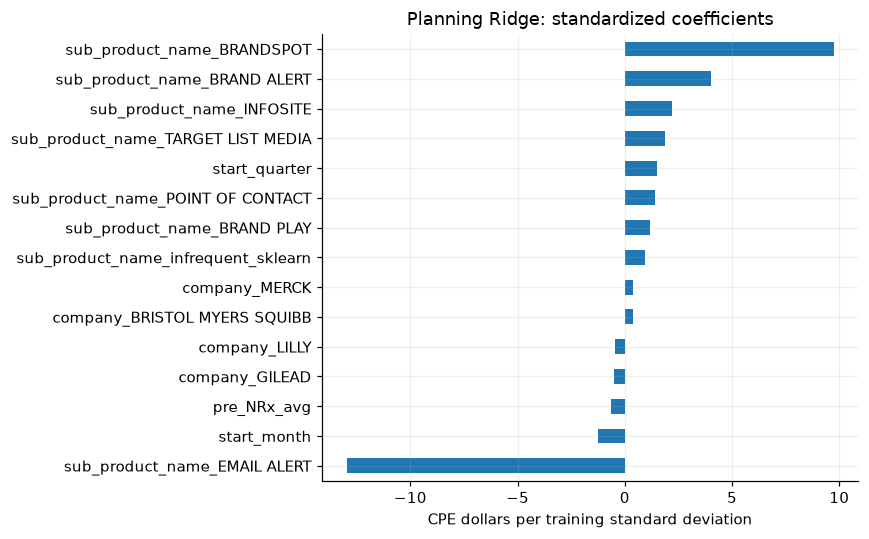

,feature,MAE_increase,std
40,sub_product_name_EMAIL ALERT,11.8261,1.2763
37,sub_product_name_BRAND ALERT,3.1363,0.3718
39,sub_product_name_BRANDSPOT,1.7935,0.0105
2,start_month,1.0005,0.1557
1,start_quarter,0.9203,0.1483
43,sub_product_name_TARGET LIST MEDIA,0.8554,0.0883
41,sub_product_name_INFOSITE,0.6817,0.0558
38,sub_product_name_BRAND PLAY,0.6778,0.0421
44,sub_product_name_infrequent_sklearn,0.4046,0.0175
42,sub_product_name_POINT OF CONTACT,0.1874,0.0177


In [10]:
coefs = pd.Series(planning_model.named_steps['model'].coef_, index=planning_cols)
top = coefs.abs().nlargest(15).index
coefs.loc[top].sort_values().plot.barh(figsize=(8, 5), title='Planning Ridge: standardized coefficients')
plt.xlabel('CPE dollars per training standard deviation'); plt.tight_layout(); plt.show()
perm = permutation_importance(planning_model, X_val[planning_cols], y_val,
                              scoring='neg_mean_absolute_error', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({'feature': planning_cols, 'MAE_increase': perm.importances_mean,
                           'std': perm.importances_std}).sort_values('MAE_increase', ascending=False)
display(importance.head(15).round(4))


## 9. Experiment report

| Experiment | Validation MAE ($) | R-squared | Finding |
|---|---:|---:|---|
| Mean baseline | 16.9905 | -0.0287 | A single average missed product-level price differences |
| Product median lookup | 0.0000 | 1.0000 | Product medians matched the validation prices |
| All-feature OLS | 0.0000 | 1.0000 | Target-derived and outcome features limited interpretation |
| OLS with Timothy's exclusions | 0.9115 | 0.9748 | Strong fit, but campaign outcomes remained among inputs |
| Ridge with Timothy's exclusions | 0.8964 | 0.9757 | Regularization modestly improved comparable OLS |
| Ridge excluding the $11 row | 0.0001 | 1.0000 | Results were sensitive to one rare training label |
| Product-only OLS | 0.1024 | 0.9992 | Product category explained nearly all validation variation |
| Ridge product ablation | 8.8094 | 0.6330 | Removing specified product indicators substantially increased error |
| Ridge planning candidates | 1.1858 | 0.9935 | Restricted inputs performed well but did not beat the lookup |
| Ridge observed labels only | 3.0351 | 0.8542 | Excluding calculated training labels increased average error |

Values were rounded to four decimals; displayed zero did not necessarily imply exact floating-point equality.

**Main finding:** CPE in this sample behaved primarily like a product price list. A product-only linear model performed very well, and the training-median product lookup performed best. The more complex regressions did not demonstrate additional predictive value over that lookup on this validation set. Ridge provided a small improvement over OLS with the same broader feature set, while label sensitivity and ablation experiments explained important sources of variation in performance.

**Scope and limitations:** validation contained only three price levels and two $68 examples. Calculated labels, rare-category grouping, correlated inputs, and repeated inspection of validation limited generalization claims. CV used pre-encoded training data and shuffled folds rather than a fully date-aware preprocessing pipeline. The analysis did not establish performance for new prices, engagement volume, prescription lift, ROI, or H2 total spend, and it did not verify availability of every candidate planning feature.

A final forecasting evaluation remained outside this experiment's scope. It would require a confirmed target and prediction-time feature set, independently justified label handling, preprocessing fitted within date-aware folds, and an untouched test set.


,experiment,MAE,RMSE,R2,within_$1,negative_predictions,notes
0,E0a Mean baseline,16.9905,18.9281,-0.0287,0.0000,0,
1,E0b Product lookup,0.0000,0.0000,1.0000,1.0000,0,Training-only product medians
2,E1 OLS all features,0.0000,0.0000,1.0000,1.0000,0,Includes target-derived and outcome features
3,E2 OLS Timothy exclusions,0.9115,2.9626,0.9748,0.8780,1,
4,E3 Ridge Timothy exclusions,0.8964,2.9083,0.9757,0.8902,1,
5,E4 Ridge without $11,0.0001,0.0001,1.0000,1.0000,0,Sensitivity only; both unusual training labels...
6,E5 Product-only OLS,0.1024,0.5356,0.9992,0.9634,0,
7,E6 Ridge product ablation,8.8094,11.3048,0.6330,0.0732,5,Matches Timothy ablation; other product proxie...
8,E7 Ridge planning candidates,1.1858,1.5053,0.9935,0.5244,0,All training labels; candidate availability ne...
9,E8 Ridge observed labels only,3.0351,7.1262,0.8542,0.7805,0,Training uses originally observed CPE only


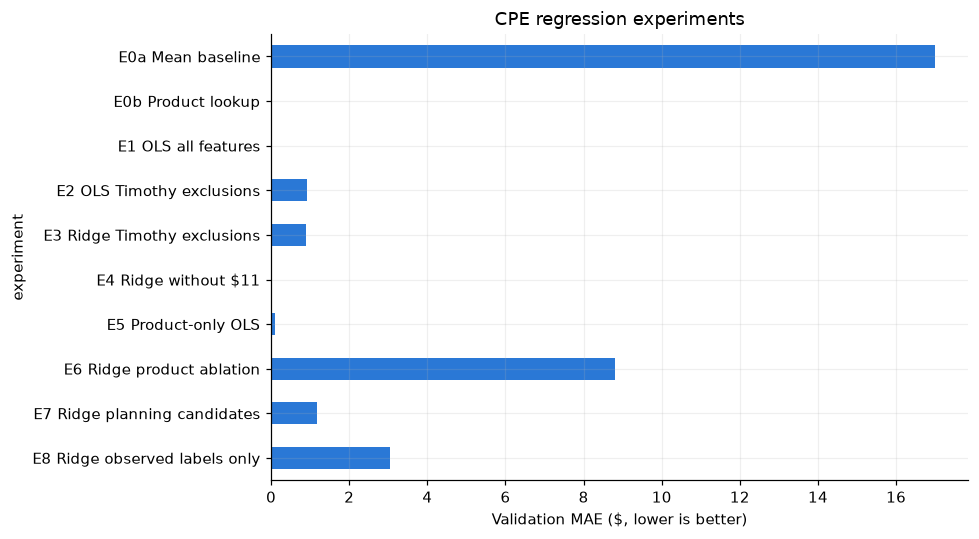

In [11]:
results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.set_index('experiment')['MAE'].iloc[::-1].plot.barh(figsize=(9, 5), color='#2a78d6')
plt.xlabel('Validation MAE ($, lower is better)'); plt.title('CPE regression experiments')
plt.tight_layout(); plt.show()
# Optional: uncomment to save results in the current working directory.
# results_df.to_csv('BakariKerr_CPE_Regression_results.csv', index=False)
# diagnostics.to_csv('BakariKerr_CPE_Regression_validation_predictions.csv', index=False)
